# ExtraaLearn Project

## Context

The EdTech industry has been surging in the past decade immensely, and according to a forecast, the Online Education market would be worth $286.62bn by 2023 with a compound annual growth rate (CAGR) of 10.26% from 2018 to 2023. The modern era of online education has enforced a lot in its growth and expansion beyond any limit. Due to having many dominant features like ease of information sharing, personalized learning experience, transparency of assessment, etc, it is now preferable to traditional education. 

In the present scenario due to the Covid-19, the online education sector has witnessed rapid growth and is attracting a lot of new customers. Due to this rapid growth, many new companies have emerged in this industry. With the availability and ease of use of digital marketing resources, companies can reach out to a wider audience with their offerings. The customers who show interest in these offerings are termed as leads. There are various sources of obtaining leads for Edtech companies, like

* The customer interacts with the marketing front on social media or other online platforms. 
* The customer browses the website/app and downloads the brochure
* The customer connects through emails for more information.

The company then nurtures these leads and tries to convert them to paid customers. For this, the representative from the organization connects with the lead on call or through email to share further details.

## Objective

ExtraaLearn is an initial stage startup that offers programs on cutting-edge technologies to students and professionals to help them upskill/reskill. With a large number of leads being generated on a regular basis, one of the issues faced by ExtraaLearn is to identify which of the leads are more likely to convert so that they can allocate resources accordingly. You, as a data scientist at ExtraaLearn, have been provided the leads data to:
* Analyze and build an ML model to help identify which leads are more likely to convert to paid customers, 
* Find the factors driving the lead conversion process
* Create a profile of the leads which are likely to convert


## Data Description

The data contains the different attributes of leads and their interaction details with ExtraaLearn. The detailed data dictionary is given below.


**Data Dictionary**
* ID: ID of the lead
* age: Age of the lead
* current_occupation: Current occupation of the lead. Values include 'Professional','Unemployed',and 'Student'
* first_interaction: How did the lead first interacted with ExtraaLearn. Values include 'Website', 'Mobile App'
* profile_completed: What percentage of profile has been filled by the lead on the website/mobile app. Values include Low - (0-50%), Medium - (50-75%), High (75-100%)
* website_visits: How many times has a lead visited the website
* time_spent_on_website: Total time spent on the website
* page_views_per_visit: Average number of pages on the website viewed during the visits.
* last_activity: Last interaction between the lead and ExtraaLearn. 
    * Email Activity: Seeking for details about program through email, Representative shared information with lead like brochure of program , etc 
    * Phone Activity: Had a Phone Conversation with representative, Had conversation over SMS with representative, etc
    * Website Activity: Interacted on live chat with representative, Updated profile on website, etc

* print_media_type1: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Newspaper.
* print_media_type2: Flag indicating whether the lead had seen the ad of ExtraaLearn in the Magazine.
* digital_media: Flag indicating whether the lead had seen the ad of ExtraaLearn on the digital platforms.
* educational_channels: Flag indicating whether the lead had heard about ExtraaLearn in the education channels like online forums, discussion threads, educational websites, etc.
* referral: Flag indicating whether the lead had heard about ExtraaLearn through reference.
* status: Flag indicating whether the lead was converted to a paid customer or not.

## Importing necessary libraries and data

In [1]:
#Install any missing libraries
%pip install xgboost -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# One consistent palette for every chart: blue = converted / main series, orange = not converted
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8a85"
STATUS_COLORS = {0: ORANGE, 1: BLUE}
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#cccccc", "grid.color": "#e6e6e6",
                                     "axes.spines.top": False, "axes.spines.right": False})

In [3]:
from pathlib import Path

# Works from notebooks/ (VS Code project layout: data/ExtraaLearn.csv) or with the CSV alongside the notebook
DATA_PATH = next(p for p in [Path("../data/ExtraaLearn.csv"), Path("data/ExtraaLearn.csv"), Path("ExtraaLearn.csv")] if p.exists())
data = pd.read_csv(DATA_PATH)
df = data.copy()  # keep the raw data untouched

## Data Overview

- Observations
- Sanity checks

In [4]:
print("Shape:", df.shape)
df.head()

Shape: (4612, 15)


,ID,age,current_occupation,first_interaction,profile_completed,website_visits,time_spent_on_website,page_views_per_visit,last_activity,print_media_type1,print_media_type2,digital_media,educational_channels,referral,status
0,EXT001,57,Unemployed,Website,High,7,1639,1.861,Website Activity,Yes,No,Yes,No,No,1
1,EXT002,56,Professional,Mobile App,Medium,2,83,0.320,Website Activity,No,No,No,Yes,No,0
2,EXT003,52,Professional,Website,Medium,3,330,0.074,Website Activity,No,No,Yes,No,No,0
3,EXT004,53,Unemployed,Website,High,4,464,2.057,Website Activity,No,No,No,No,No,1
4,EXT005,23,Student,Website,High,4,600,16.914,Email Activity,No,No,No,No,No,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4612 entries, 0 to 4611
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     4612 non-null   str    
 1   age                    4612 non-null   int64  
 2   current_occupation     4612 non-null   str    
 3   first_interaction      4612 non-null   str    
 4   profile_completed      4612 non-null   str    
 5   website_visits         4612 non-null   int64  
 6   time_spent_on_website  4612 non-null   int64  
 7   page_views_per_visit   4612 non-null   float64
 8   last_activity          4612 non-null   str    
 9   print_media_type1      4612 non-null   str    
 10  print_media_type2      4612 non-null   str    
 11  digital_media          4612 non-null   str    
 12  educational_channels   4612 non-null   str    
 13  referral               4612 non-null   str    
 14  status                 4612 non-null   int64  
dtypes: float64(1), 

In [6]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Unique IDs:", df["ID"].nunique(), "of", len(df))

Missing values: 0
Duplicate rows: 0
Unique IDs: 4612 of 4612


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,4612.0,46.201214,13.161454,18.0,36.00000,51.000,57.00000,63.000
website_visits,4612.0,3.566782,2.829134,0.0,2.00000,3.000,5.00000,30.000
time_spent_on_website,4612.0,724.011275,743.828683,0.0,148.75000,376.000,1336.75000,2537.000
page_views_per_visit,4612.0,3.026126,1.968125,0.0,2.07775,2.792,3.75625,18.434
status,4612.0,0.298569,0.457680,0.0,0.00000,0.000,1.00000,1.000


In [8]:
cat_cols = ["current_occupation", "first_interaction", "profile_completed", "last_activity",
            "print_media_type1", "print_media_type2", "digital_media", "educational_channels", "referral", "status"]
for c in cat_cols:
    print(df[c].value_counts(normalize=True).round(3), "\n")

current_occupation
Professional    0.567
Unemployed      0.312
Student         0.120
Name: proportion, dtype: float64 

first_interaction
Website       0.551
Mobile App    0.449
Name: proportion, dtype: float64 

profile_completed
High      0.491
Medium    0.486
Low       0.023
Name: proportion, dtype: float64 

last_activity
Email Activity      0.494
Phone Activity      0.268
Website Activity    0.239
Name: proportion, dtype: float64 

print_media_type1
No     0.892
Yes    0.108
Name: proportion, dtype: float64 

print_media_type2
No     0.949
Yes    0.051
Name: proportion, dtype: float64 

digital_media
No     0.886
Yes    0.114
Name: proportion, dtype: float64 

educational_channels
No     0.847
Yes    0.153
Name: proportion, dtype: float64 

referral
No     0.98
Yes    0.02
Name: proportion, dtype: float64 

status
0    0.701
1    0.299
Name: proportion, dtype: float64 



In [9]:
# Leads with zero website visits also have zero time on site; they are split across both first-interaction channels
print("Zero website visits:", (df.website_visits == 0).sum())
print("Zero time on website:", (df.time_spent_on_website == 0).sum())
print("Zero page views/visit:", (df.page_views_per_visit == 0).sum())
df[df.website_visits == 0].first_interaction.value_counts()

Zero website visits: 174
Zero time on website: 174
Zero page views/visit: 181


first_interaction
Website       100
Mobile App     74
Name: count, dtype: int64

In [10]:
# ID is a unique identifier with no predictive value
df.drop(columns="ID", inplace=True)

**Observations:**
- 4,612 leads and 15 columns: an ID, 4 numeric features, 9 categorical features and the target `status`.
- No missing values and no duplicates. `ID` is unique per row and is dropped.
- About **29.9% of leads converted**, so the classes are imbalanced (roughly 70/30). Models should be judged on recall/F1 for the converted class, not just accuracy.
- Age ranges 18–63 (median 51); the lead base skews towards mid-career adults.
- `website_visits` (max 30) and `page_views_per_visit` (max ~18) are right-skewed with a long tail; `time_spent_on_website` ranges 0–2,537.
- 174 leads have zero website visits and zero time on site, split across both first-interaction channels (100 Website, 74 Mobile App). They are kept as valid records. A further 7 leads have visits but zero page views per visit.
- Professionals are the largest group (57%), then Unemployed (31%) and Students (12%).
- Very few leads have a Low profile completion (2%) or came via referral (2%).

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

### Univariate analysis

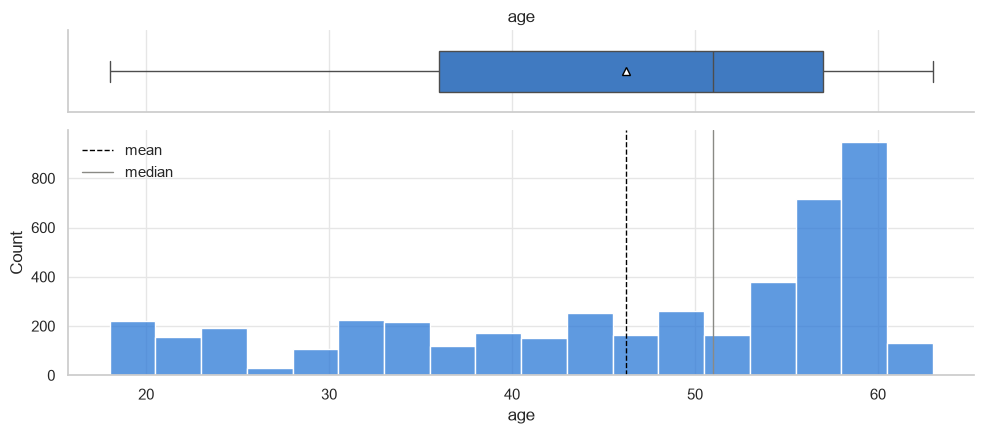

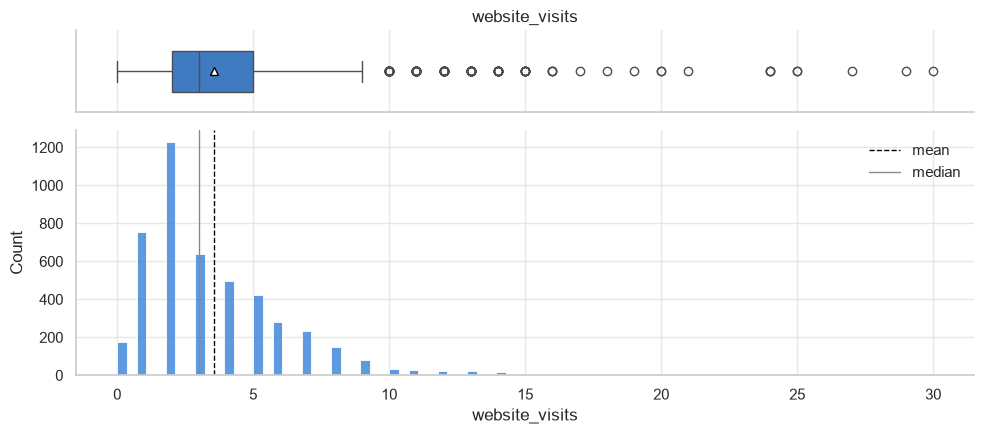

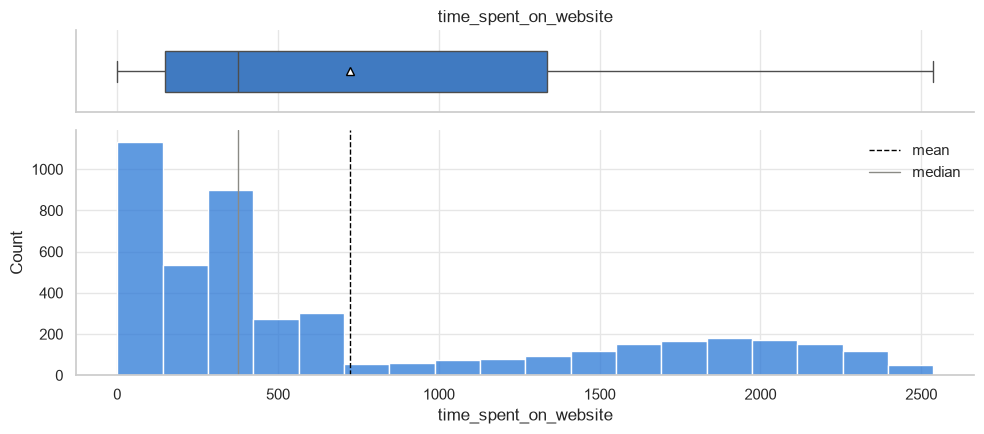

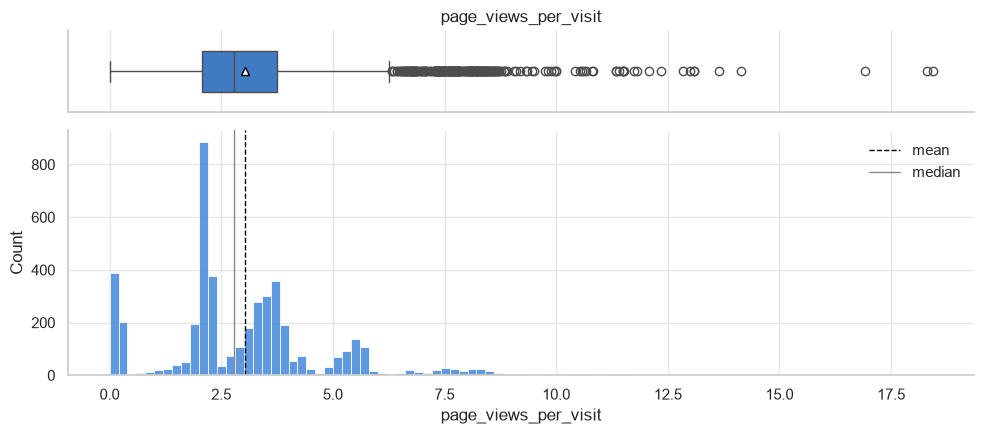

In [11]:
num_cols = ["age", "website_visits", "time_spent_on_website", "page_views_per_visit"]

def hist_box(col):
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True,
                                          gridspec_kw={"height_ratios": (0.25, 0.75)})
    sns.boxplot(x=df[col], ax=ax_box, color=BLUE, showmeans=True, width=0.5,
                meanprops={"markerfacecolor": "white", "markeredgecolor": "black"})
    sns.histplot(df[col], ax=ax_hist, color=BLUE, kde=False, edgecolor="white")
    ax_hist.axvline(df[col].mean(), color="black", ls="--", lw=1, label="mean")
    ax_hist.axvline(df[col].median(), color=GREY, ls="-", lw=1, label="median")
    ax_hist.legend(frameon=False)
    ax_box.set_title(col)
    plt.tight_layout(); plt.show()

for c in num_cols:
    hist_box(c)

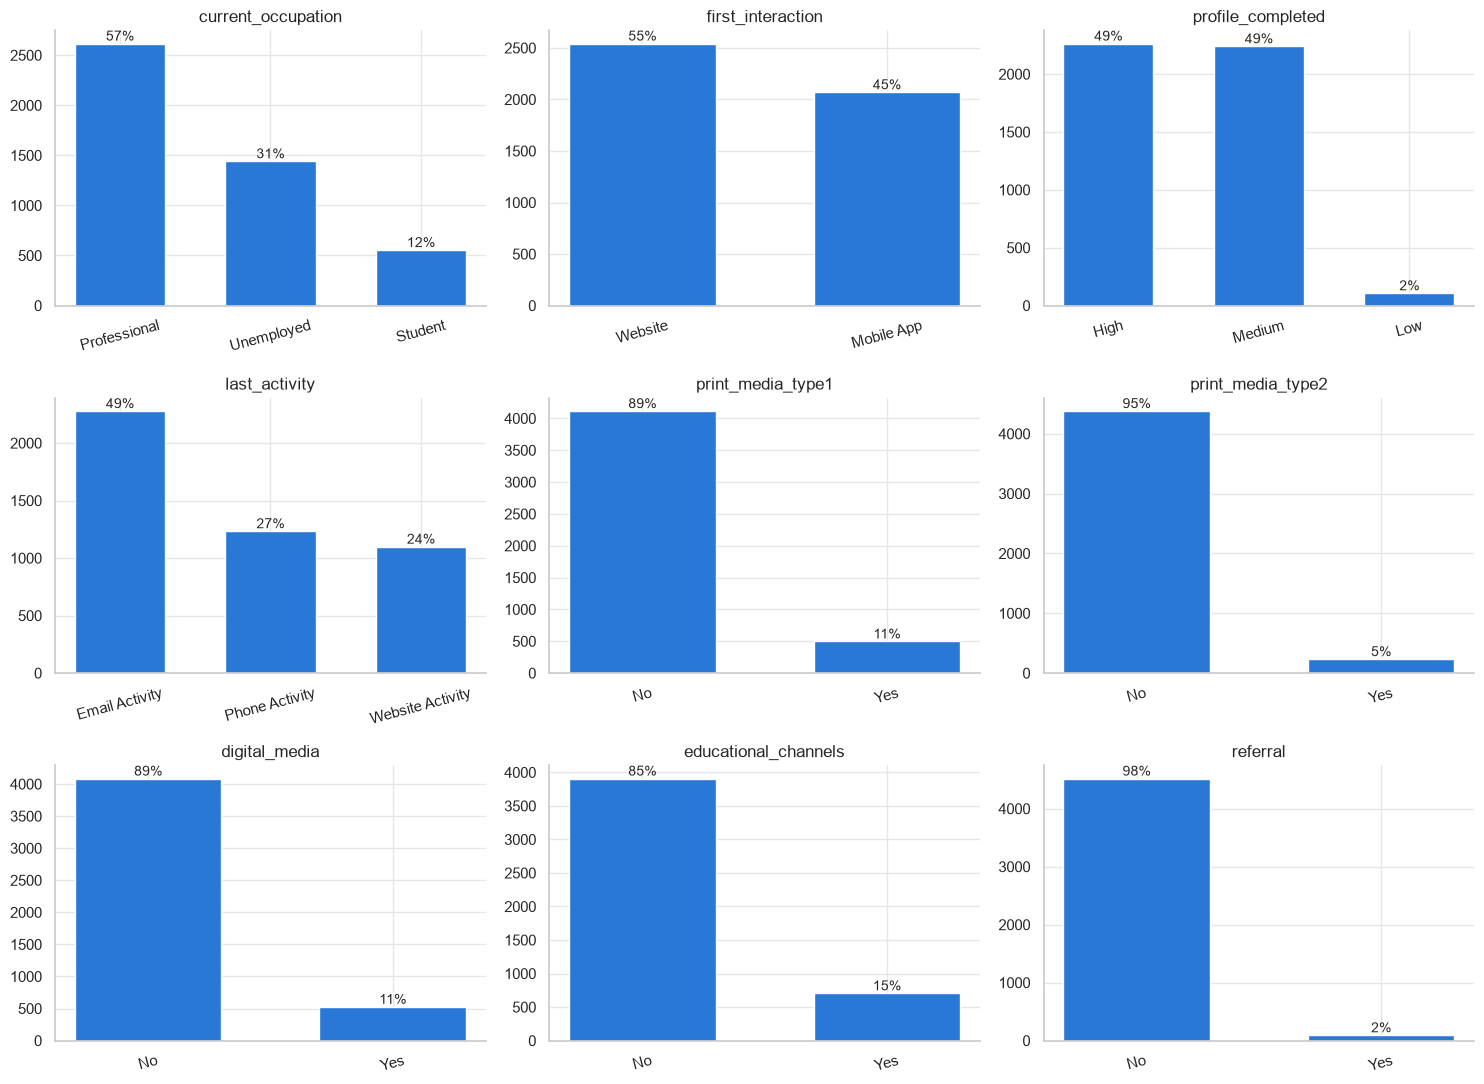

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.flat, cat_cols[:-1]):
    counts = df[c].value_counts()
    ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v / len(df):.0%}", ha="center", va="bottom", fontsize=10)
    ax.set_title(c); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

**Observations (univariate):**
- Age is bimodal: a small student cluster around 18–25 and a large block of older adults, most heavily 56–60.
- Most leads visit the website 1–5 times (0 to 30, median 3). The data for website_visits are right-skewed; visits above 9 are statistical outliers but plausible real behaviour, so they are kept.
- Time on site is spread widely with a peak near zero (light browsers) and a long plateau of engaged visitors.
- Page views per visit cluster around 2–4, with a tail of very heavy browsers.
- First interaction is split fairly evenly between Website (55%) and Mobile App (45%).
- Email is the most common last activity (49%), then Phone (27%) and Website (24%).
- Each advertising/referral channel reaches only a minority of leads (2–15%).

### Bivariate analysis

In [13]:
def conversion_bar(col, ax=None, order=None):
    """Conversion rate (% of leads converted) per category, with lead counts."""
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4))
    g = df.groupby(col)["status"].agg(["mean", "count"])
    if order is not None:
        g = g.loc[order]
    ax.bar(g.index.astype(str), g["mean"] * 100, color=BLUE, width=0.6)
    ax.axhline(df.status.mean() * 100, color=GREY, ls="--", lw=1, label="overall rate")
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(i, m * 100 + 1, f"{m:.1%}\n(n={n})", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, max(g["mean"]) * 100 + 18)
    ax.set_ylabel("Conversion rate (%)"); ax.set_xlabel(""); ax.set_title(col)
    ax.legend(frameon=False, loc="upper left")
    if show:
        plt.tight_layout(); plt.show()
    return g

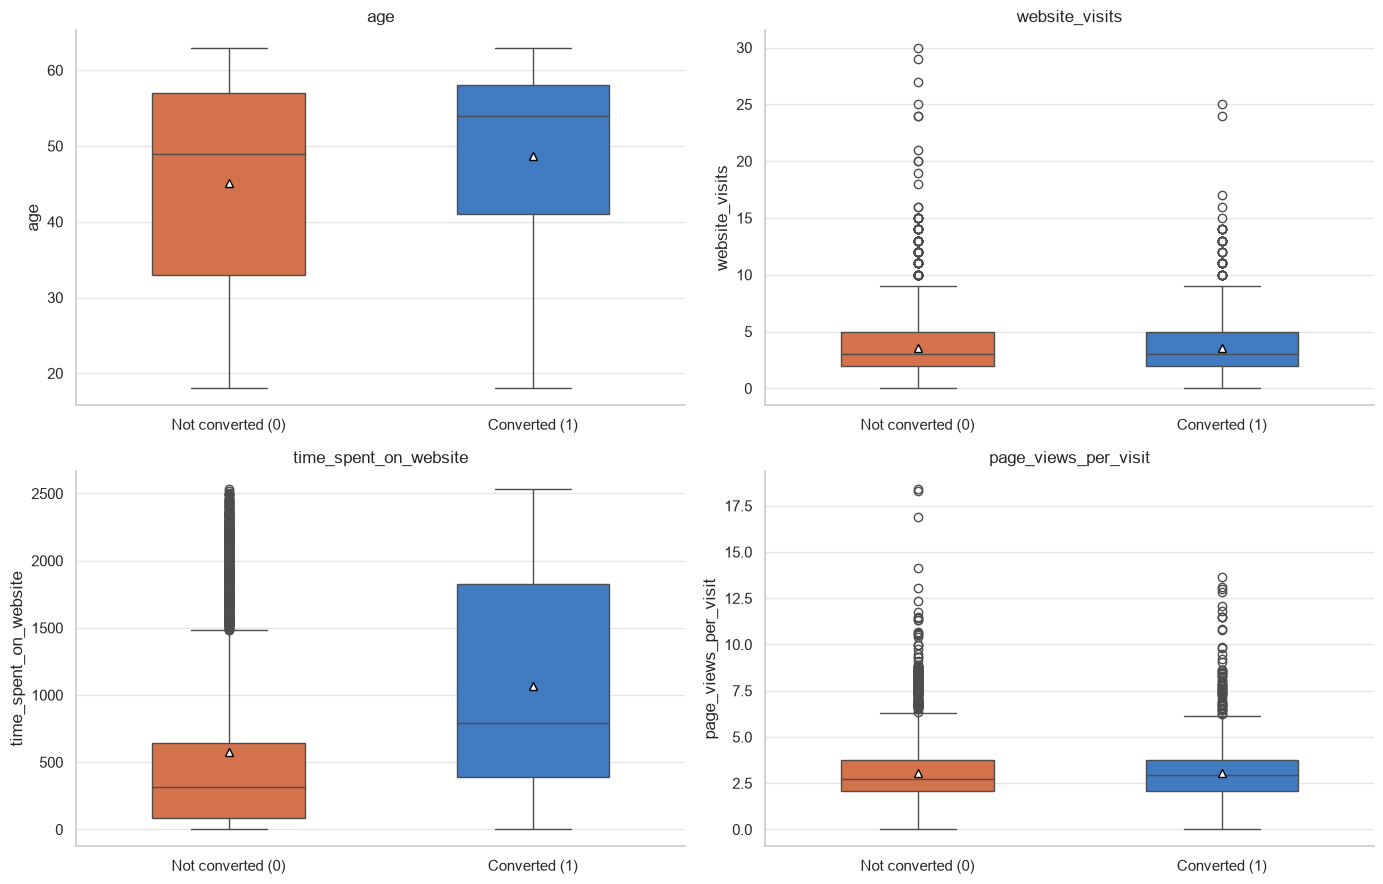

,age,website_visits,time_spent_on_website,page_views_per_visit
status,,,,
0,49.0,3.0,317.0,2.706
1,54.0,3.0,789.0,2.935


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="status", y=c, hue="status", legend=False, ax=ax, palette=[ORANGE, BLUE], showmeans=True, width=0.5,
                meanprops={"markerfacecolor": "white", "markeredgecolor": "black"})
    ax.set_xticklabels(["Not converted (0)", "Converted (1)"]); ax.set_xlabel(""); ax.set_title(c)
plt.tight_layout(); plt.show()
df.groupby("status")[num_cols].median()

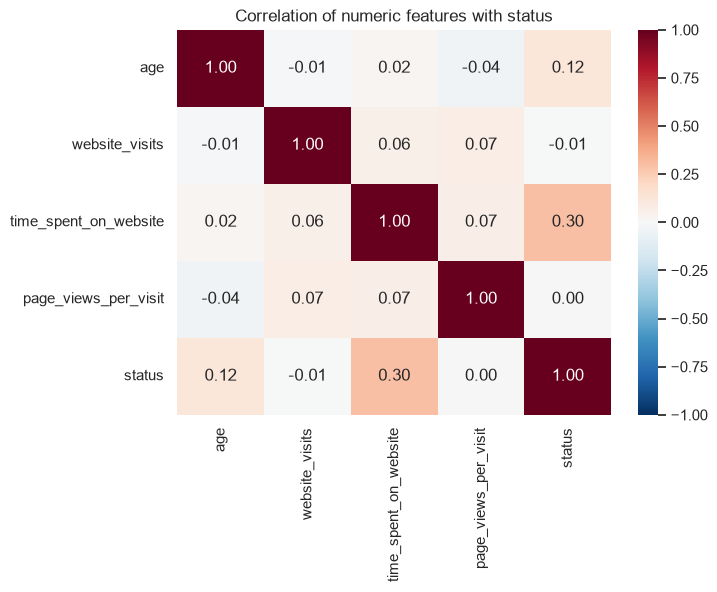

In [15]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["status"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation of numeric features with status"); plt.show()

**Observations (numeric vs status):**
- **Time spent on the website is the strongest numeric signal**: converted leads spent a median of ~789 vs ~317 for those who did not convert (correlation with status 0.30).
- Converted leads are older on average (median 54 vs 49).
- Website visits and page views per visit look almost identical between the two groups, so on their own they say little about conversion.
- The numeric features are not strongly correlated with each other, so there is no multicollinearity concern.

#### Q1. How does current occupation affect lead status?

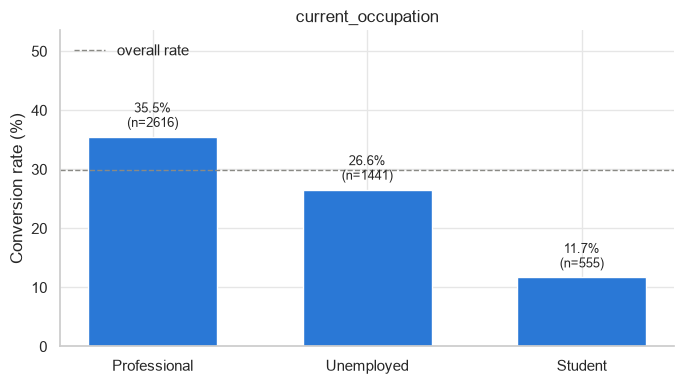

,mean,count
current_occupation,,
Professional,0.355122,2616
Unemployed,0.265788,1441
Student,0.117117,555


In [16]:
conversion_bar("current_occupation", order=["Professional", "Unemployed", "Student"])

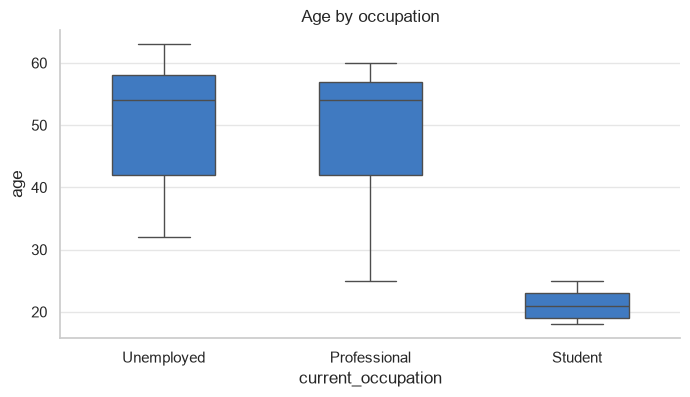

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="current_occupation", y="age", color=BLUE, width=0.5, ax=ax)
ax.set_title("Age by occupation"); plt.show()

**Observations:**
- **Professionals convert best (35.5%)**, then Unemployed (26.6%). **Students convert least (11.7%)**.
- Professionals are likely looking to upskill for career growth and have the means to pay; students may be price-sensitive or exploring.
- Age and occupation are closely linked: students are all 18–25, so the age effect above is partly an occupation effect.

#### Q2. Does the first channel of interaction affect lead status?

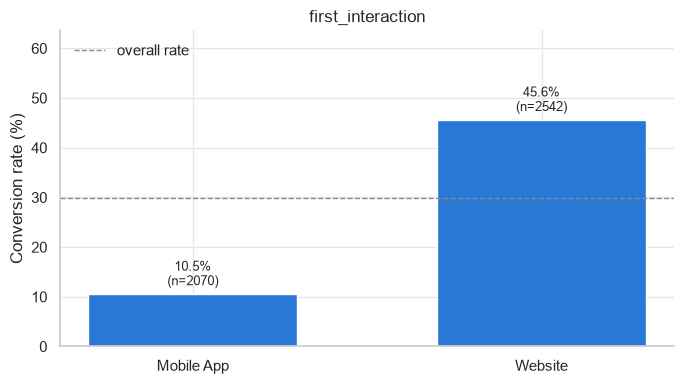

,mean,count
first_interaction,,
Mobile App,0.105314,2070
Website,0.455940,2542


In [18]:
conversion_bar("first_interaction")

**Observations:**
- Type of first interaction matters a lot: **leads whose first interaction was the Website converted at 45.6%, versus only 10.5% for the Mobile App**, more than four times higher.
- This suggests the mobile app experience is not converting interest into purchase and is worth investigating.

#### Q3. Which way of interaction works best?

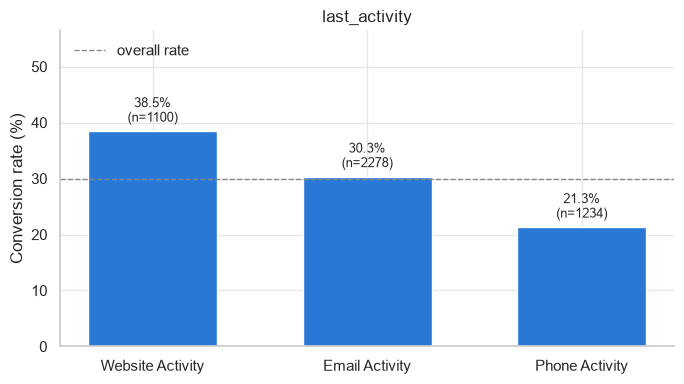

,mean,count
last_activity,,
Website Activity,0.384545,1100
Email Activity,0.303336,2278
Phone Activity,0.213128,1234


In [19]:
conversion_bar("last_activity", order=["Website Activity", "Email Activity", "Phone Activity"])

**Observations:**
- **Website activity (live chat, profile updates) converts best at 38.5%**, then Email (30.3%). Phone/SMS has the lowest rate (21.3%).
- Leads who engage on the website themselves are more self-motivated. Phone outreach may be reaching less-interested leads, or the call process itself may need improving.

#### Q4. Which lead channels have the highest conversion rate?

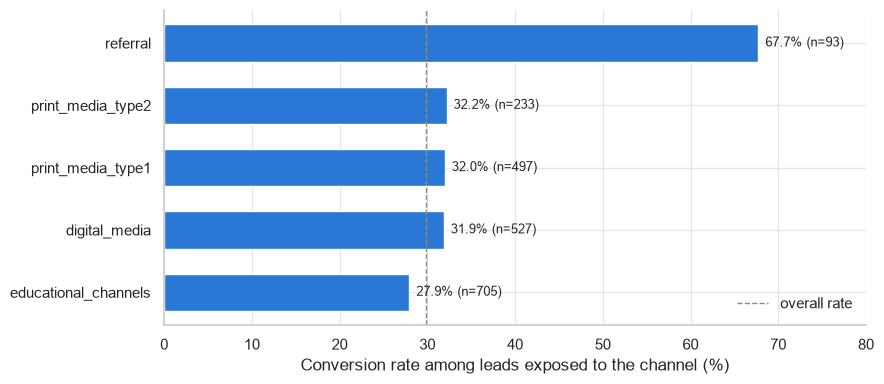

,rate_if_yes,rate_if_no,leads_yes
channel,,,
referral,0.677,0.291,93
print_media_type2,0.322,0.297,233
print_media_type1,0.320,0.296,497
digital_media,0.319,0.296,527
educational_channels,0.279,0.302,705


In [20]:
channels = ["print_media_type1", "print_media_type2", "digital_media", "educational_channels", "referral"]
rows = []
for c in channels:
    g = df.groupby(c)["status"].agg(["mean", "count"])
    rows.append({"channel": c, "rate_if_yes": g.loc["Yes", "mean"], "rate_if_no": g.loc["No", "mean"],
                 "leads_yes": g.loc["Yes", "count"]})
ch = pd.DataFrame(rows).set_index("channel").sort_values("rate_if_yes", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ch.index[::-1], ch.rate_if_yes[::-1] * 100, color=BLUE, height=0.6)
ax.axvline(df.status.mean() * 100, color=GREY, ls="--", lw=1, label="overall rate")
for i, (r, n) in enumerate(zip(ch.rate_if_yes[::-1], ch.leads_yes[::-1])):
    ax.text(r * 100 + 0.8, i, f"{r:.1%} (n={n})", va="center", fontsize=9)
ax.set_xlabel("Conversion rate among leads exposed to the channel (%)"); ax.set_xlim(0, 80)
ax.legend(frameon=False); plt.tight_layout(); plt.show()
ch.round(3)

In [21]:
from scipy.stats import chi2_contingency
pd.Series({c: chi2_contingency(pd.crosstab(df[c], df.status))[1] for c in channels}, name="chi2 p-value").round(4)

print_media_type1       0.2941
print_media_type2       0.4686
digital_media           0.3044
educational_channels    0.2454
referral                0.0000
Name: chi2 p-value, dtype: float64

**Observations:**
- **Referral is by far the strongest channel: 67.7% of referred leads converted**, more than double the overall rate. It is, however, tiny (93 leads, 2%).
- Newspaper, magazine and digital ads each lift conversion only slightly (about 32% vs 30%) and the differences are not statistically significant (chi-square p > 0.05). Educational channels are slightly below average.
- Growing the referral programme looks like the highest-value channel investment.

#### Q5. Does having more details about a prospect increase the chance of conversion?

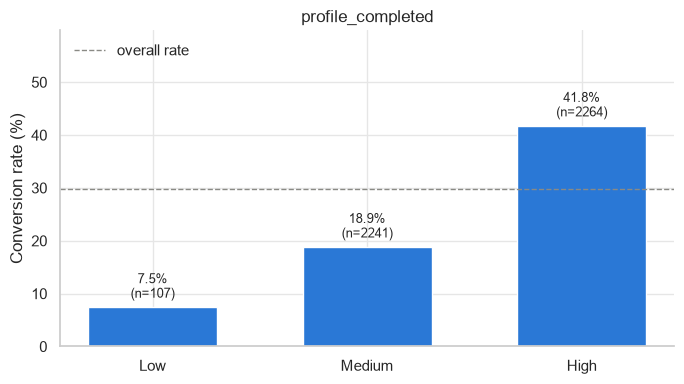

,mean,count
profile_completed,,
Low,0.074766,107
Medium,0.188755,2241
High,0.417845,2264


In [22]:
conversion_bar("profile_completed", order=["Low", "Medium", "High"])

**Observations:**
- **Yes, prospect detail strongly increases chance of conversion.** Conversion rises from 7.5% (Low) to 18.9% (Medium) to **41.8% (High)** profile completion.
- Profile completion is both a signal of intent and something the company can encourage (nudges, incentives to finish the profile).

### Further analysis

In [23]:
# Interaction of the two strongest categorical drivers
pd.crosstab([df.first_interaction], [df.profile_completed], values=df.status, aggfunc="mean").round(3)[["Low", "Medium", "High"]]

profile_completed,Low,Medium,High
first_interaction,,,
Mobile App,0.000,0.102,0.113
Website,0.127,0.260,0.665


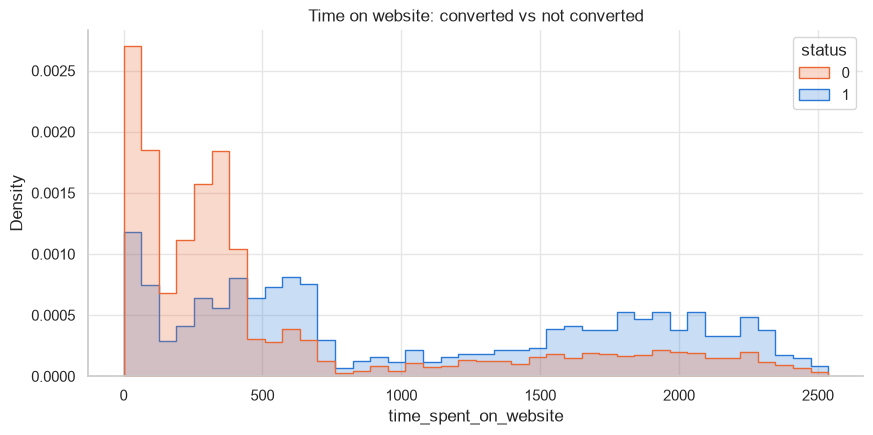

,mean,count
time_spent_on_website,,
"(-1, 250]",0.151,1516
"(250, 500]",0.185,1206
"(500, 1000]",0.504,546
"(1000, 1500]",0.408,306
"(1500, 3000]",0.506,1038


In [24]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=df, x="time_spent_on_website", hue="status", palette=STATUS_COLORS, bins=40,
             element="step", stat="density", common_norm=False, ax=ax)
ax.set_title("Time on website: converted vs not converted"); plt.show()
bins = pd.cut(df.time_spent_on_website, [-1, 250, 500, 1000, 1500, 3000])
df.groupby(bins)["status"].agg(["mean", "count"]).round(3)

**EDA summary with key observations:**
- The strongest single signals are **first interaction via Website**, **High profile completion**, **time on website above ~500**, **referral**, and **Professional occupation**.
- Website-first leads with a High profile convert at 66.5%, while Mobile App leads convert at 11% or less whatever their profile.
- Conversion jumps from under 20% to around 50% once time on the website passes roughly 500.
- Advertising channels (print, digital, educational) show little measurable effect on conversion.
- Visits and page views per visit carry little standalone signal; the models will show whether they help in combination.

## Data Preprocessing

- Missing value treatment (if needed)
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling 
- Any other preprocessing steps (if needed)

In [25]:
# Outlier check (IQR rule) on numeric features
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c:25s} outliers: {n_out:4d} ({n_out / len(df):.1%})")

age                       outliers:    0 (0.0%)
website_visits            outliers:  154 (3.3%)
time_spent_on_website     outliers:    0 (0.0%)
page_views_per_visit      outliers:  257 (5.6%)


**Observations:**
- No missing values, so no imputation is needed.
- Duplicates and identifiers: there are no duplicates, and `ID` was dropped because it has no predictive value.
- Outliers: found only in website visits (3.3%) and page views per visit (5.6%). They were kept because they are genuine behaviour and the tree models are insensitive to them.
- No new features are engineered: the raw features are already interpretable and the tree models capture interactions themselves.
- Encoding: the 9 categorical features are one-hot encoded with the first level dropped, giving 16 model features.
- Train/test split: 70/30, stratified on `status` (3,228 training and 1,384 test leads). The conversion rate is preserved (29.9% train, 29.8% test).
- Class imbalance: handled with `class_weight='balanced'` (and `scale_pos_weight` for XGBoost) and a recall-based decision threshold. Gradient Boosting has no class weighting and relies on the threshold alone.
- Scaling: applied only for Logistic Regression, because tree models do not need it.

In [26]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, roc_auc_score,
                             confusion_matrix, precision_recall_curve, roc_curve)

X = pd.get_dummies(df.drop(columns="status"), drop_first=True, dtype=int)
y = df["status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Conversion rate - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))
X.columns.tolist()

Train: (3228, 16)  Test: (1384, 16)
Conversion rate - train: 0.299, test: 0.298


['age',
 'website_visits',
 'time_spent_on_website',
 'page_views_per_visit',
 'current_occupation_Student',
 'current_occupation_Unemployed',
 'first_interaction_Website',
 'profile_completed_Low',
 'profile_completed_Medium',
 'last_activity_Phone Activity',
 'last_activity_Website Activity',
 'print_media_type1_Yes',
 'print_media_type2_Yes',
 'digital_media_Yes',
 'educational_channels_Yes',
 'referral_Yes']

### Evaluation criterion

The model can make two kinds of mistake:
- **False negative**: predicting a lead will not convert when it would have. The company under-invests in a real customer and **loses revenue**. This is the costlier mistake.
- **False positive**: predicting a lead will convert when it won't. A representative spends time on a lead that does not pay.

So the priority is **recall on the converted class** (catch as many real converters as possible), while keeping precision reasonable so the sales team's effort isn't wasted. F1 and ROC-AUC are used to compare models overall.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

def scores(model, X_, y_, threshold=0.5):
    p = (model.predict_proba(X_)[:, 1] >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y_, p), "Recall": recall_score(y_, p),
            "Precision": precision_score(y_, p), "F1": f1_score(y_, p),
            "ROC-AUC": roc_auc_score(y_, model.predict_proba(X_)[:, 1])}

def performance(model, threshold=0.5, name=None):
    """Train vs test metrics plus confusion matrices."""
    res = pd.DataFrame({"Train": scores(model, X_train, y_train, threshold),
                        "Test": scores(model, X_test, y_test, threshold)}).T.round(3)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, (lbl, X_, y_) in zip(axes, [("Train", X_train, y_train), ("Test", X_test, y_test)]):
        p = (model.predict_proba(X_)[:, 1] >= threshold).astype(int)
        cm = confusion_matrix(y_, p)
        annot = np.array([[f"{v}\n{v / cm.sum():.1%}" for v in row] for row in cm])
        sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["Not converted", "Converted"], yticklabels=["Not converted", "Converted"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{name or ''} {lbl}".strip())
    plt.tight_layout(); plt.show()
    return res

def plot_importance(model, title, top=12):
    imp = pd.Series(model.feature_importances_, index=X_train.columns).sort_values().tail(top)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
    for i, v in enumerate(imp.values):
        ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_title(title); ax.set_xlabel("Importance")
    plt.tight_layout(); plt.show()
    return imp.sort_values(ascending=False)

## Building a Decision Tree model

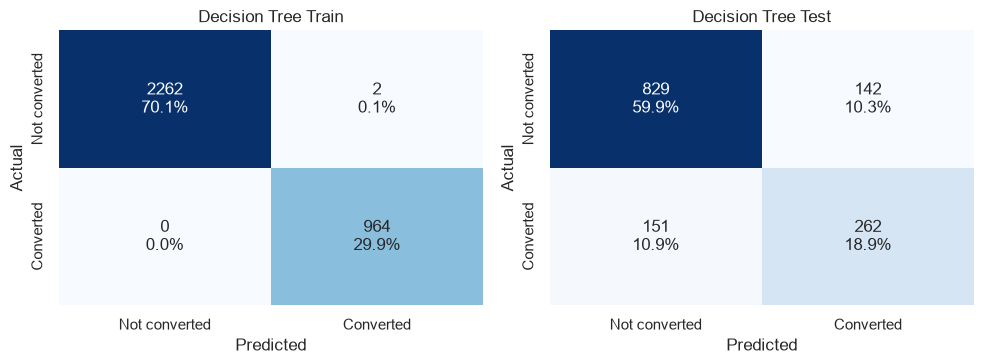

,Accuracy,Recall,Precision,F1,ROC-AUC
Train,0.999,1.000,0.998,0.999,1.000
Test,0.788,0.634,0.649,0.641,0.744


In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# class_weight="balanced" up-weights the minority (converted) class
dt = DecisionTreeClassifier(class_weight="balanced", random_state=1)
dt.fit(X_train, y_train)
performance(dt, name="Decision Tree")

**Observations:**
- The default tree **overfits badly**: it is perfect on the training data (recall 1.00) but recall drops to 0.63 on the test set, so it misses over a third of real converters.
- An unconstrained tree memorises the training leads. It needs limits on depth and leaf size.

## Model Performance evaluation and improvement

#### Hyperparameter tuning with GridSearchCV

GridSearchCV tries **every combination** in the grid below, scoring each with 5-fold stratified cross-validation on the training data only.

- `max_depth` limits how many questions the tree can ask, the main control on overfitting.
- `min_samples_leaf` stops the tree from creating leaves for a handful of leads.
- `criterion` is the impurity measure used to choose splits (Gini or entropy).

**Scoring metric: ROC-AUC.** It measures how well the tree ranks converters above non-converters regardless of the cut-off, rewarding trees that are good at both catching converters and avoiding false alarms. The cut-off is then set separately to reach the recall target (see *Choosing the decision threshold*). Scoring directly on recall is shown below for comparison: it favours a very shallow tree that flags too many leads.

Combinations evaluated: 100
Best parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 40}
Best CV ROC-AUC: 0.919


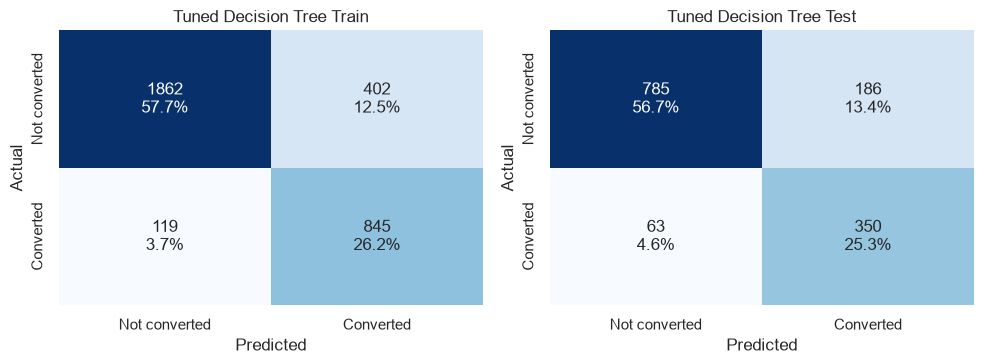

,Accuracy,Recall,Precision,F1,ROC-AUC
Train,0.839,0.877,0.678,0.764,0.926
Test,0.820,0.847,0.653,0.738,0.911


In [29]:
dt_grid = {"max_depth": range(2, 12), "min_samples_leaf": [1, 5, 10, 20, 40], "criterion": ["gini", "entropy"]}
dt_search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=1), dt_grid,
                         scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)
dt_tuned = dt_search.best_estimator_
print("Combinations evaluated:", len(dt_search.cv_results_["params"]))
print("Best parameters:", dt_search.best_params_)
print(f"Best CV ROC-AUC: {dt_search.best_score_:.3f}")
performance(dt_tuned, name="Tuned Decision Tree")

In [30]:
# Top 5 grid combinations by CV ROC-AUC, with the spread across folds
res = pd.DataFrame(dt_search.cv_results_)
res[["param_max_depth", "param_min_samples_leaf", "param_criterion", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").head(5).round(4)

,param_max_depth,param_min_samples_leaf,param_criterion,mean_test_score,std_test_score,rank_test_score
19,5,40,gini,0.9194,0.0104,1
29,7,40,gini,0.9190,0.0105,2
69,5,40,entropy,0.9188,0.0100,3
79,7,40,entropy,0.9186,0.0102,4
24,6,40,gini,0.9185,0.0121,5


In [31]:
# For comparison: the same grid scored on recall alone
dt_recall_search = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=1), dt_grid,
                                scoring="recall", cv=cv, n_jobs=-1).fit(X_train, y_train)
print("Best parameters when scoring on recall:", dt_recall_search.best_params_)
pd.DataFrame({"Tuned on ROC-AUC": scores(dt_tuned, X_test, y_test),
              "Tuned on recall": scores(dt_recall_search.best_estimator_, X_test, y_test)}).T.round(3)

Best parameters when scoring on recall: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}


,Accuracy,Recall,Precision,F1,ROC-AUC
Tuned on ROC-AUC,0.820,0.847,0.653,0.738,0.911
Tuned on recall,0.777,0.889,0.583,0.704,0.874


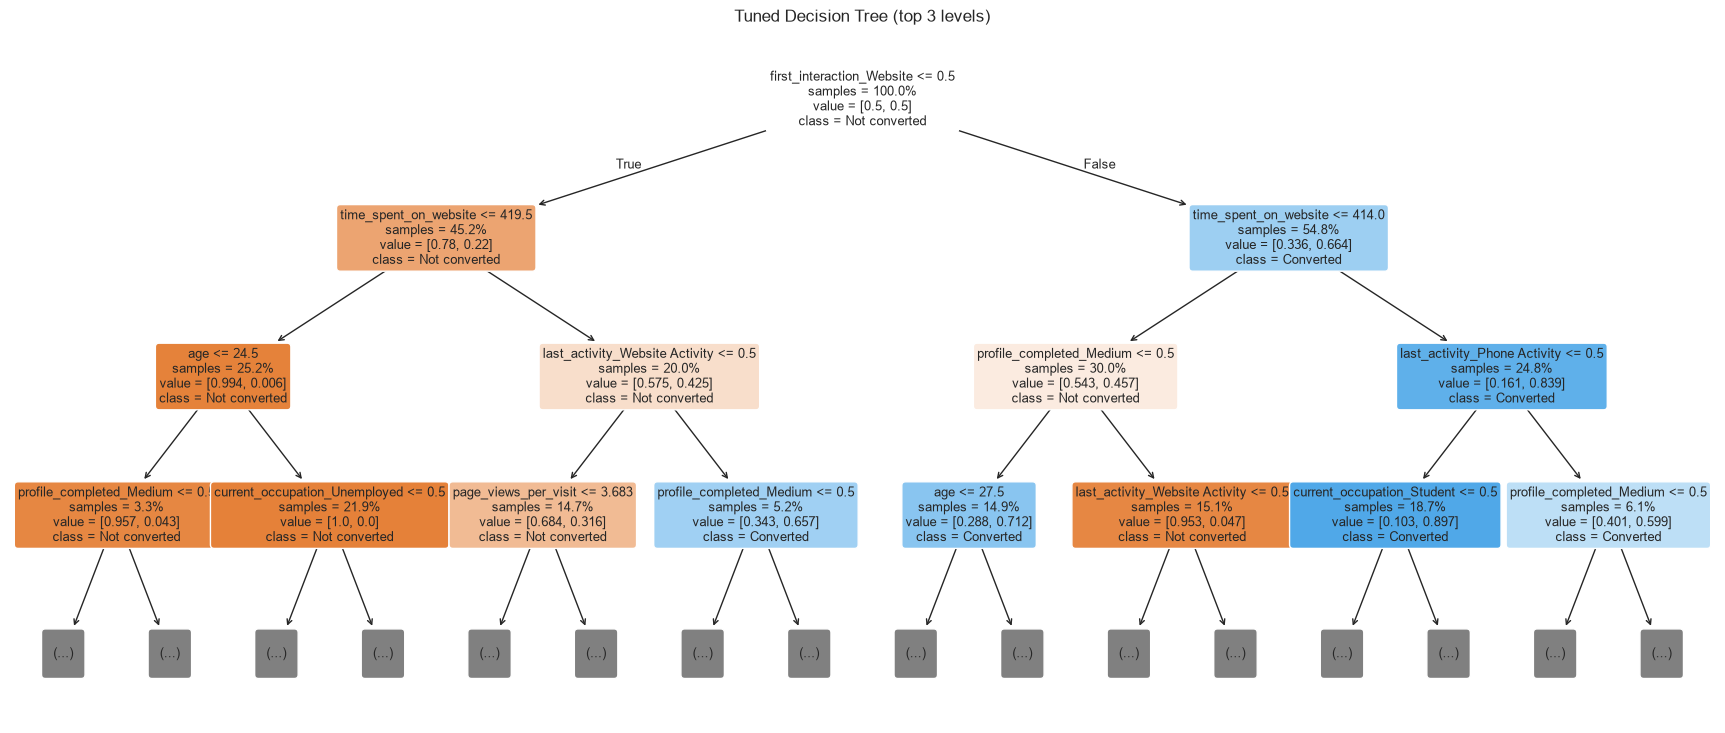

In [32]:
plt.figure(figsize=(22, 9))
plot_tree(dt_tuned, max_depth=3, feature_names=X_train.columns.tolist(), class_names=["Not converted", "Converted"],
          filled=True, rounded=True, fontsize=9, proportion=True, impurity=False)
plt.title("Tuned Decision Tree (top 3 levels)"); plt.show()

In [33]:
print(export_text(dt_tuned, feature_names=X_train.columns.tolist(), max_depth=3))

|--- first_interaction_Website <= 0.50
|   |--- time_spent_on_website <= 419.50
|   |   |--- age <= 24.50
|   |   |   |--- profile_completed_Medium <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- profile_completed_Medium >  0.50
|   |   |   |   |--- class: 0
|   |   |--- age >  24.50
|   |   |   |--- current_occupation_Unemployed <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- current_occupation_Unemployed >  0.50
|   |   |   |   |--- class: 0
|   |--- time_spent_on_website >  419.50
|   |   |--- last_activity_Website Activity <= 0.50
|   |   |   |--- page_views_per_visit <= 3.68
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- page_views_per_visit >  3.68
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- last_activity_Website Activity >  0.50
|   |   |   |--- profile_completed_Medium <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- profile_completed_Medium >  0.50
|   |   |   |   |--- class: 1
|--- first_interaction_W

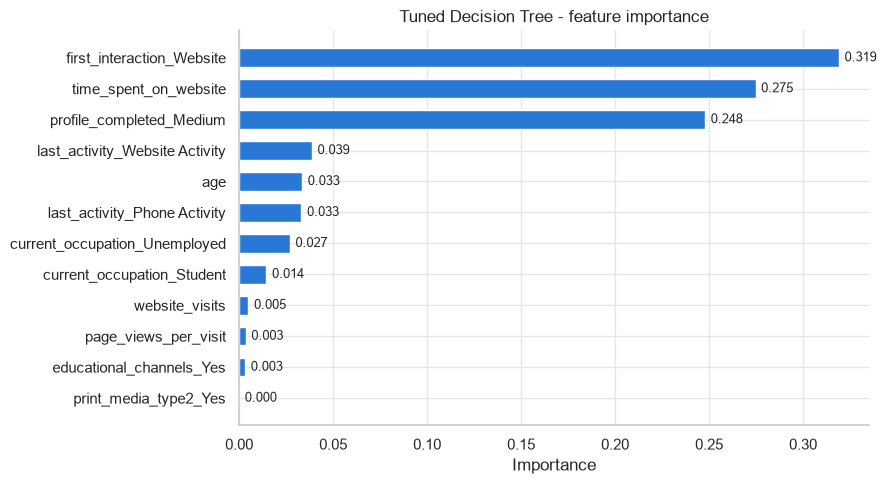

first_interaction_Website         0.319
time_spent_on_website             0.275
profile_completed_Medium          0.248
last_activity_Website Activity    0.039
age                               0.033
last_activity_Phone Activity      0.033
current_occupation_Unemployed     0.027
current_occupation_Student        0.014
dtype: float64

In [34]:
dt_imp = plot_importance(dt_tuned, "Tuned Decision Tree - feature importance")
dt_imp.head(8).round(3)

**Observations:**
- GridSearchCV evaluated all 100 combinations and selected **max_depth = 5, min_samples_leaf = 40, criterion = gini** (CV ROC-AUC 0.919). The top five combinations are all depth 5 to 7 with min_samples_leaf = 40, so the choice is stable.
- Limiting the tree to **depth 5 with at least 40 leads per leaf** removes the overfitting: recall is 0.88 on train and **0.85 on test**, with ROC-AUC rising from 0.74 to 0.91.
- Precision is 0.65, meaning about two in three leads flagged as likely converters do convert, more than double the 30% base rate.
- **Why ROC-AUC rather than recall for tuning:** scoring the grid on recall alone picks a depth-3 tree that catches 89% of converters but with only 58% precision and a much lower ROC-AUC (0.87). That tree flags far more leads that never convert. Tuning on ROC-AUC and then setting the cut-off for recall gives a better balance.
- The tree splits first on **first interaction (Website vs Mobile App)**, then on **time spent on the website (around 415–420)**, then on **profile completion**, last activity and age.
- Those three features carry about 84% of the tree's importance. Last activity, age and occupation refine the prediction; the advertising channel flags contribute almost nothing.

## Building a Random Forest model

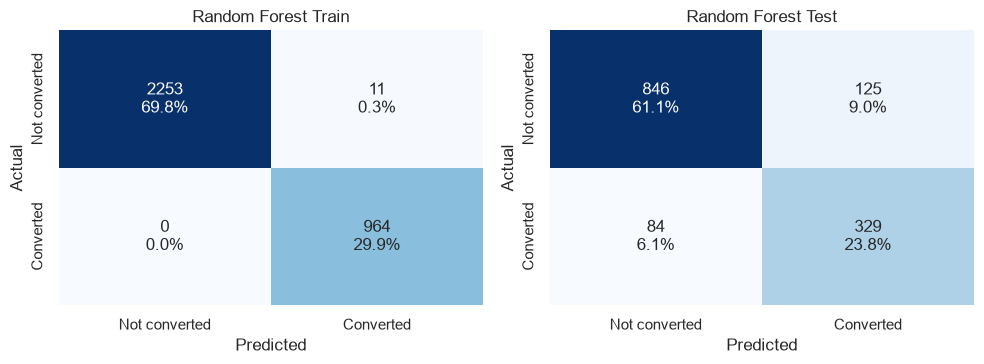

,Accuracy,Recall,Precision,F1,ROC-AUC
Train,0.997,1.000,0.989,0.994,1.000
Test,0.849,0.797,0.725,0.759,0.916


In [35]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight="balanced", random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
performance(rf, name="Random Forest")

**Observations**
- The default Random Forest also **overfits** (train recall 1.00, test 0.80), though it generalises much better than a single tree (test ROC-AUC 0.92).

## Model Performance evaluation and improvement

#### Hyperparameter tuning with GridSearchCV

GridSearchCV evaluates **every combination** below (2 x 4 x 4 x 3 = 96 candidate forests) with 5-fold stratified cross-validation on the training data, scored on **ROC-AUC** for the same reason as the Decision Tree: it rewards forests that rank converters above non-converters, and the cut-off is then set for the recall target.

- `n_estimators`: number of trees. More trees give more stable predictions.
- `max_depth`: depth of each tree, the main control on overfitting.
- `min_samples_leaf`: minimum leads per leaf, which smooths predictions.
- `max_features`: share of features each split may consider. Smaller values make the trees more different from each other, which helps the average.

This takes about 2 to 3 minutes.

Combinations evaluated: 96
Best parameters: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 500}
Best CV ROC-AUC: 0.9293


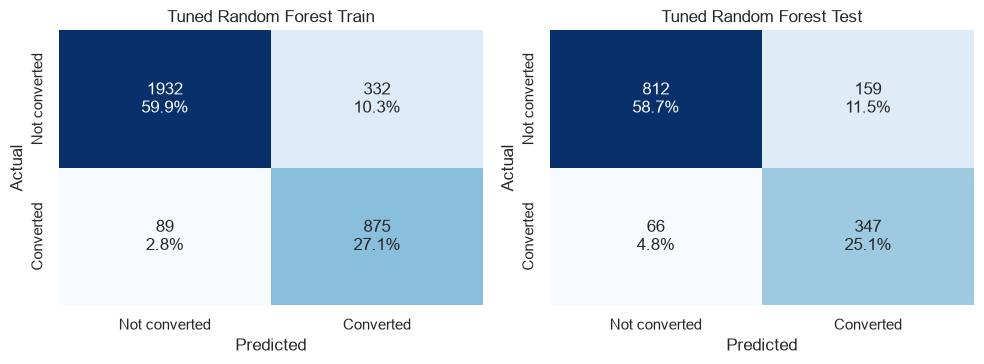

,Accuracy,Recall,Precision,F1,ROC-AUC
Train,0.870,0.908,0.725,0.806,0.962
Test,0.837,0.840,0.686,0.755,0.925


In [36]:
rf_grid = {"n_estimators": [200, 500], "max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 3, 5, 10],
           "max_features": ["sqrt", 0.5, 0.7]}
rf_search = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=1, n_jobs=1), rf_grid,
                         scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)
rf_tuned = rf_search.best_estimator_
print("Combinations evaluated:", len(rf_search.cv_results_["params"]))
print("Best parameters:", rf_search.best_params_)
print(f"Best CV ROC-AUC: {rf_search.best_score_:.4f}")
performance(rf_tuned, name="Tuned Random Forest")

In [37]:
# Top 5 grid combinations by CV ROC-AUC, with the spread across folds
res = pd.DataFrame(rf_search.cv_results_)
res[["param_n_estimators", "param_max_depth", "param_min_samples_leaf", "param_max_features",
     "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score").head(5).round(4)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score,rank_test_score
51,500,8,3,sqrt,0.9293,0.0073,1
33,500,6,1,0.5,0.9292,0.0072,2
41,500,6,1,0.7,0.9290,0.0069,3
34,200,6,3,0.5,0.9289,0.0073,4
35,500,6,3,0.5,0.9289,0.0075,5


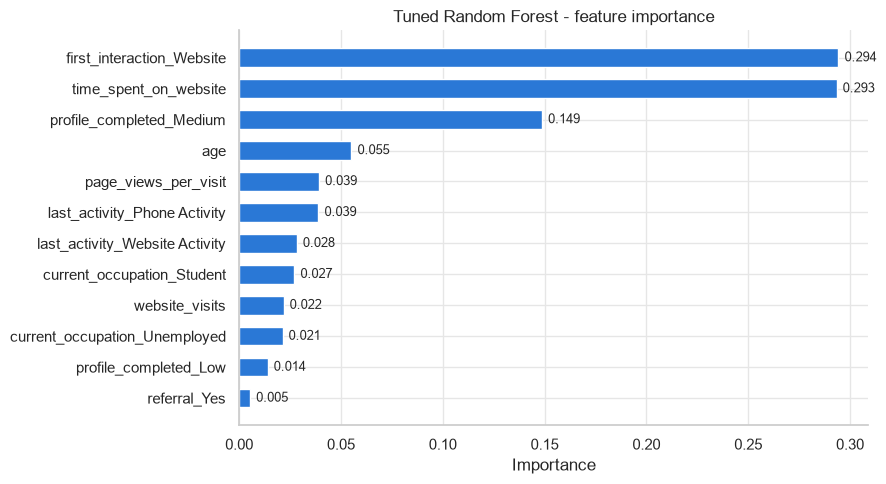

first_interaction_Website         0.294
time_spent_on_website             0.293
profile_completed_Medium          0.149
age                               0.055
page_views_per_visit              0.039
last_activity_Phone Activity      0.039
last_activity_Website Activity    0.028
current_occupation_Student        0.027
dtype: float64

In [38]:
rf_imp = plot_importance(rf_tuned, "Tuned Random Forest - feature importance")
rf_imp.head(8).round(3)

**Observations:**
- GridSearchCV evaluated all 96 combinations and selected **500 trees, max_depth = 8, min_samples_leaf = 3, max_features = "sqrt"** (CV ROC-AUC 0.929).
- The top five combinations are within 0.0005 of each other, far less than the fold-to-fold spread (about 0.007). So the forest's performance is **not sensitive to the exact settings**, as long as the trees are depth-limited (6 to 8).
- Tuning controls the overfitting of the default forest: recall goes from 1.00 on train vs 0.80 on test (default) to **0.91 on train vs 0.84 on test**, and test ROC-AUC improves from 0.916 to **0.925**.
- At the default 0.5 cut-off the tuned forest catches 84% of converters with 69% precision. Compared with the tuned Decision Tree, recall is about the same with **higher precision (0.69 vs 0.65)** and a **higher ROC-AUC (0.925 vs 0.911)**, so it wastes fewer follow-ups on leads that will not convert.

**Feature importance:**
- **First interaction via the Website (0.29)** and **time spent on the website (0.29)** are jointly the strongest drivers, followed by **profile completion (0.15)**. Together they account for about three quarters of the forest's decisions, the same top three as the Decision Tree and the EDA.
- Age (0.06), page views per visit, and last activity (phone lowers the chance, website activity raises it) add smaller refinements.
- The advertising flags (newspaper, magazine, digital, educational channels) and referral carry almost no importance. Referral converts well but applies to only 2% of leads, so it rarely changes a prediction.
- Unlike the single tree, the forest spreads some importance across secondary features, because each tree sees a random subset of features at each split. This makes it more robust than relying on one tree's structure.

## Additional models: Logistic Regression, Gradient Boosting and XGBoost

To check whether a different algorithm does better, three more models are tuned with the same 5-fold CV and ROC-AUC scoring, using RandomizedSearchCV (40 sampled combinations; all 20 values of C for Logistic Regression) instead of a full grid. Logistic regression gives a linear baseline. Gradient Boosting and XGBoost are boosted tree ensembles, often the strongest on tabular data.

In [39]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

lr_search = RandomizedSearchCV(make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
                               {"logisticregression__C": np.logspace(-3, 2, 20)},
                               n_iter=40, scoring="roc_auc", cv=cv, random_state=1, n_jobs=-1).fit(X_train, y_train)
lr_tuned = lr_search.best_estimator_

gb_grid = {"n_estimators": [100, 200, 300], "learning_rate": [0.03, 0.05, 0.1], "max_depth": [2, 3, 4],
           "subsample": [0.7, 0.9, 1.0], "min_samples_leaf": [1, 10, 20]}
gb_search = RandomizedSearchCV(GradientBoostingClassifier(random_state=1), gb_grid,
                               n_iter=40, scoring="roc_auc", cv=cv, random_state=1, n_jobs=-1).fit(X_train, y_train)
gb_tuned = gb_search.best_estimator_

spw = (y_train == 0).sum() / (y_train == 1).sum()  # balance classes, like class_weight="balanced"
xgb_grid = {"n_estimators": [100, 200, 300], "learning_rate": [0.03, 0.05, 0.1], "max_depth": [2, 3, 4, 5],
            "subsample": [0.7, 0.9, 1.0], "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 5, 10]}
xgb_search = RandomizedSearchCV(XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=1, n_jobs=-1),
                                xgb_grid, n_iter=40, scoring="roc_auc", cv=cv, random_state=1, n_jobs=-1).fit(X_train, y_train)
xgb_tuned = xgb_search.best_estimator_

for n, s in [("Logistic Regression", lr_search), ("Gradient Boosting", gb_search), ("XGBoost", xgb_search)]:
    print(f"{n}: CV ROC-AUC {s.best_score_:.3f}  {s.best_params_}")

Logistic Regression: CV ROC-AUC 0.868  {'logisticregression__C': np.float64(0.02069138081114789)}
Gradient Boosting: CV ROC-AUC 0.930  {'subsample': 0.9, 'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 4, 'learning_rate': 0.03}
XGBoost: CV ROC-AUC 0.930  {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


## Choosing the decision threshold

Models trained with balanced class weights already lean towards recall, but Gradient Boosting has no class weighting, so at the default 0.5 cut-off it under-predicts converters. To compare all models on equal terms, each model's threshold is set **on the training data only** (out-of-fold CV predictions) to the highest value that still catches at least **85% of converters**. The test set is then scored at that threshold.

In [40]:
tuned = {"Logistic Regression": lr_tuned, "Decision Tree": dt_tuned, "Random Forest": rf_tuned,
         "Gradient Boosting": gb_tuned, "XGBoost": xgb_tuned}
cv_auc = {"Logistic Regression": lr_search.best_score_, "Decision Tree": dt_search.best_score_,
          "Random Forest": rf_search.best_score_, "Gradient Boosting": gb_search.best_score_, "XGBoost": xgb_search.best_score_}

TARGET_RECALL = 0.85
thresholds = {}
for n, m in tuned.items():
    oof = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    thresholds[n] = thr[np.where(rec[:-1] >= TARGET_RECALL)[0][-1]]
pd.Series(thresholds, name="threshold").round(3)

Logistic Regression    0.463
Decision Tree          0.558
Random Forest          0.503
Gradient Boosting      0.347
XGBoost                0.553
Name: threshold, dtype: float64

## Model performance comparison

In [41]:
rows = {}
for n, m in tuned.items():
    tr = scores(m, X_train, y_train, thresholds[n]); te = scores(m, X_test, y_test, thresholds[n])
    rows[n] = {"CV ROC-AUC": cv_auc[n], "Train Recall": tr["Recall"], "Test Recall": te["Recall"],
               "Test Precision": te["Precision"], "Test F1": te["F1"], "Test Accuracy": te["Accuracy"], "Test ROC-AUC": te["ROC-AUC"]}
# Untuned baselines for reference (default 0.5 threshold)
for n, m in [("Decision Tree (default)", dt), ("Random Forest (default)", rf)]:
    tr = scores(m, X_train, y_train); te = scores(m, X_test, y_test)
    rows[n] = {"CV ROC-AUC": np.nan, "Train Recall": tr["Recall"], "Test Recall": te["Recall"],
               "Test Precision": te["Precision"], "Test F1": te["F1"], "Test Accuracy": te["Accuracy"], "Test ROC-AUC": te["ROC-AUC"]}
comparison = pd.DataFrame(rows).T.sort_values("Test ROC-AUC", ascending=False).round(3)
comparison

,CV ROC-AUC,Train Recall,Test Recall,Test Precision,Test F1,Test Accuracy,Test ROC-AUC
XGBoost,0.930,0.883,0.838,0.699,0.762,0.844,0.927
Random Forest,0.929,0.907,0.840,0.686,0.755,0.837,0.925
Gradient Boosting,0.930,0.887,0.833,0.691,0.755,0.839,0.924
Random Forest (default),NaN,1.000,0.797,0.725,0.759,0.849,0.916
Decision Tree,0.919,0.877,0.847,0.653,0.738,0.820,0.911
Logistic Regression,0.868,0.853,0.847,0.604,0.706,0.789,0.876
Decision Tree (default),NaN,1.000,0.634,0.649,0.641,0.788,0.744


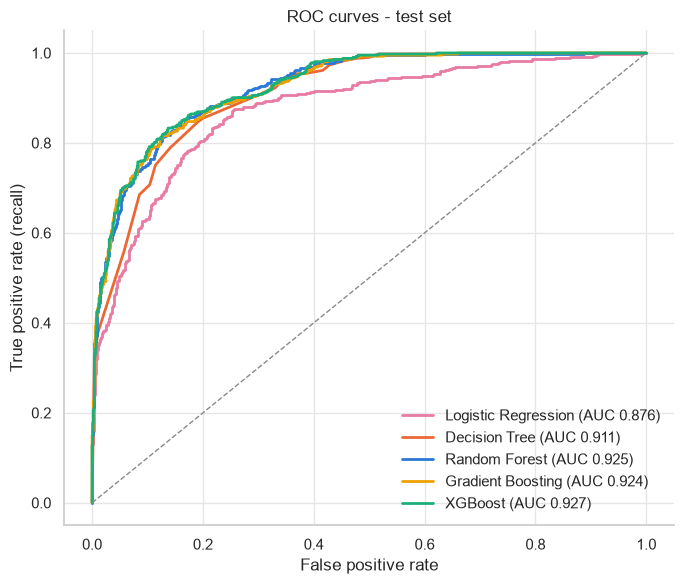

In [42]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = {"Random Forest": BLUE, "XGBoost": "#1baf7a", "Gradient Boosting": "#eda100",
          "Decision Tree": ORANGE, "Logistic Regression": "#e87ba4"}
for n, m in tuned.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, lw=2, color=colors[n], label=f"{n} (AUC {roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)"); ax.set_title("ROC curves - test set")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Observations**
- Tuning was essential: the default trees score perfectly on training data but lose 20–37 points of recall on the test set; all tuned models generalise well (train and test recall within about 7 points).
- At the same recall target (~85% of converters caught), **Random Forest, XGBoost and Gradient Boosting are effectively tied**: test ROC-AUC 0.924–0.927, precision 0.69–0.70, F1 0.76. The differences are smaller than the variation between CV folds.
- The tuned **Decision Tree** is only slightly behind (ROC-AUC 0.911, precision 0.65) and is the easiest to explain.
- **Logistic Regression** is clearly weakest (ROC-AUC 0.876, precision 0.60): conversion depends on interactions and thresholds (e.g. Website-first *and* high time on site) that a linear model can't capture.

## Random Forest vs XGBoost

XGBoost is the most widely used boosting library and is often the top performer on tabular data, so it is worth checking whether it beats the Random Forest here. Both are compared at their own 85%-recall thresholds, then fold by fold on identical cross-validation splits.

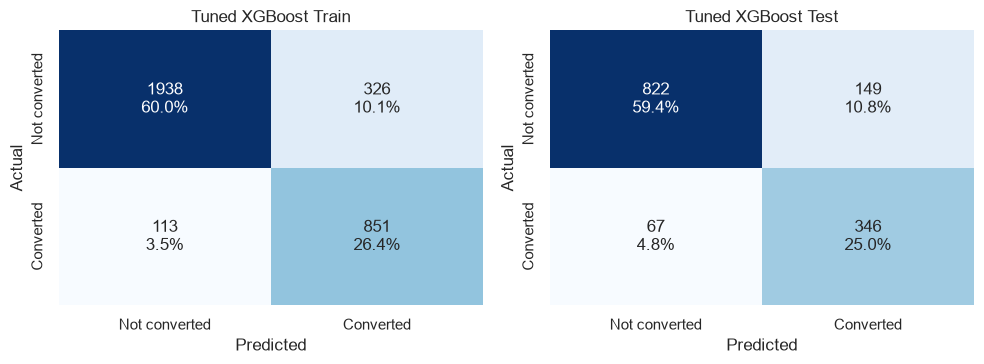

,Accuracy,Recall,Precision,F1,ROC-AUC
Train,0.864,0.883,0.723,0.795,0.953
Test,0.844,0.838,0.699,0.762,0.927


In [43]:
performance(xgb_tuned, threshold=thresholds["XGBoost"], name="Tuned XGBoost")

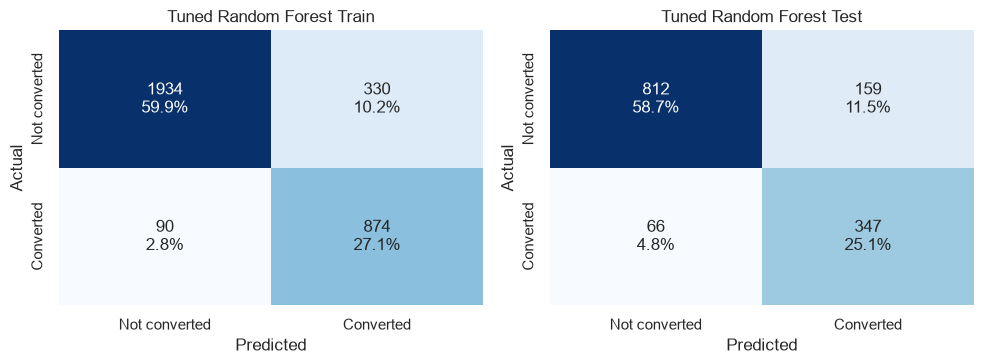

,Accuracy,Recall,Precision,F1,ROC-AUC
Train,0.870,0.907,0.726,0.806,0.962
Test,0.837,0.840,0.686,0.755,0.925


In [44]:
performance(rf_tuned, threshold=thresholds["Random Forest"], name="Tuned Random Forest")

In [45]:
from sklearn.model_selection import cross_val_score

# Same 15 folds (5-fold CV repeated with 3 seeds) for both models, so the per-fold difference isolates the algorithm
rep_cv = [StratifiedKFold(n_splits=5, shuffle=True, random_state=s) for s in range(3)]
fold = pd.DataFrame({
    "Random Forest": np.concatenate([cross_val_score(rf_tuned, X_train, y_train, cv=c, scoring="roc_auc") for c in rep_cv]),
    "XGBoost": np.concatenate([cross_val_score(xgb_tuned, X_train, y_train, cv=c, scoring="roc_auc") for c in rep_cv]),
})
fold["Difference (XGB - RF)"] = fold["XGBoost"] - fold["Random Forest"]
print(fold.describe().loc[["mean", "std", "min", "max"]].round(4))
print("\nFolds where XGBoost wins:", (fold["Difference (XGB - RF)"] > 0).sum(), "of", len(fold))

      Random Forest  XGBoost  Difference (XGB - RF)
mean         0.9281   0.9289                 0.0007
std          0.0082   0.0076                 0.0024
min          0.9117   0.9169                -0.0030
max          0.9406   0.9407                 0.0066

Folds where XGBoost wins: 10 of 15


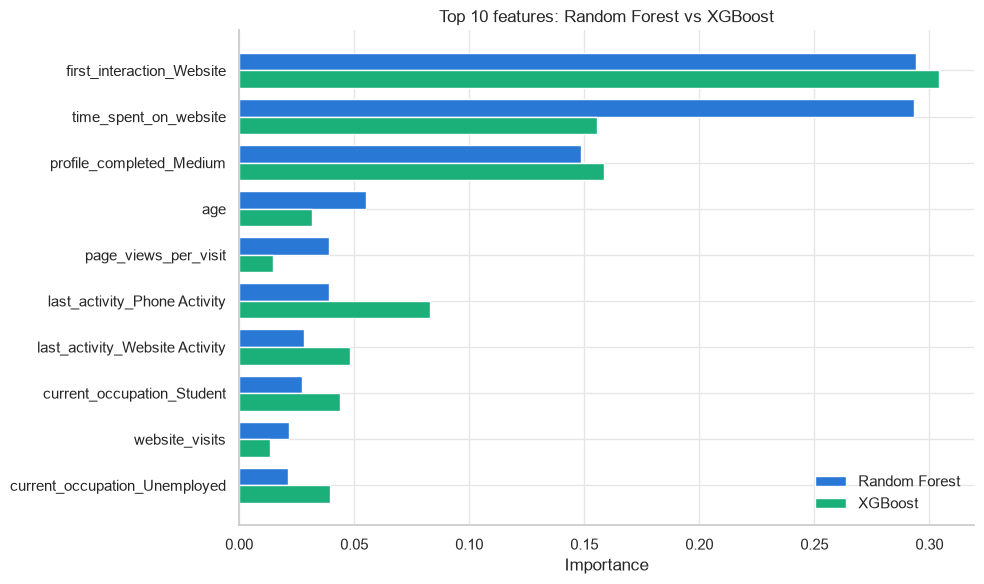

,Random Forest,XGBoost
first_interaction_Website,0.294,0.304
time_spent_on_website,0.293,0.156
profile_completed_Medium,0.149,0.158
age,0.055,0.032
page_views_per_visit,0.039,0.015
last_activity_Phone Activity,0.039,0.083
last_activity_Website Activity,0.028,0.048
current_occupation_Student,0.027,0.044
website_visits,0.022,0.013
current_occupation_Unemployed,0.021,0.039


In [46]:
imp_cmp = pd.DataFrame({"Random Forest": pd.Series(rf_tuned.feature_importances_, index=X_train.columns),
                        "XGBoost": pd.Series(xgb_tuned.feature_importances_, index=X_train.columns)})
imp_cmp = imp_cmp.loc[imp_cmp["Random Forest"].sort_values(ascending=False).index[:10]][::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ypos = np.arange(len(imp_cmp)); h = 0.38
ax.barh(ypos + h / 2, imp_cmp["Random Forest"], height=h, color=BLUE, label="Random Forest")
ax.barh(ypos - h / 2, imp_cmp["XGBoost"], height=h, color="#1baf7a", label="XGBoost")
ax.set_yticks(ypos); ax.set_yticklabels(imp_cmp.index); ax.set_xlabel("Importance")
ax.set_title("Top 10 features: Random Forest vs XGBoost"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
imp_cmp[::-1].round(3)

**Observations: XGBoost adds no meaningful gain**
- On the test set the two models are practically equivalent (Random Forest vs XGBoost): ROC-AUC **0.925 vs 0.927**, recall 0.84 vs 0.84, precision 0.69 vs 0.70, F1 0.76 vs 0.76.
- Across 15 paired cross-validation folds XGBoost is ahead by an average of only **0.0007** in ROC-AUC and wins 10 of 15 folds, but the per-fold difference varies by ±0.0024 (one standard deviation), about three times the average gap. The edge is too small to matter in practice.
- Both rank the same three features at the top (first interaction, time on website, profile completion). XGBoost spreads importance more evenly across the smaller features, but this does not translate into better predictions.
- Why boosting adds little here: the signal is concentrated in a few strong features with clear thresholds, there are only 16 features and about 3,200 training rows, and both ensembles already capture the key interactions. There is little left for boosting's sequential error-correction to find.
- With practically equal performance, the **Random Forest is preferred**: it is simpler to tune, less sensitive to hyperparameters, more robust to overfitting, and it is the model the project brief asks for.

## Final model: tuned Random Forest

The tuned Random Forest is chosen as the final model, using the 0.50 threshold chosen on the training data.

Decision threshold: 0.503


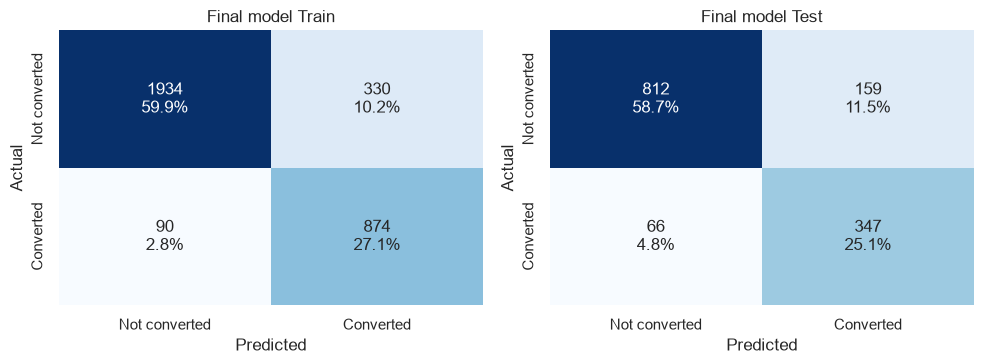

,Accuracy,Recall,Precision,F1,ROC-AUC
Train,0.870,0.907,0.726,0.806,0.962
Test,0.837,0.840,0.686,0.755,0.925


In [47]:
final_model, final_thr = rf_tuned, thresholds["Random Forest"]
print(f"Decision threshold: {final_thr:.3f}")
performance(final_model, threshold=final_thr, name="Final model")

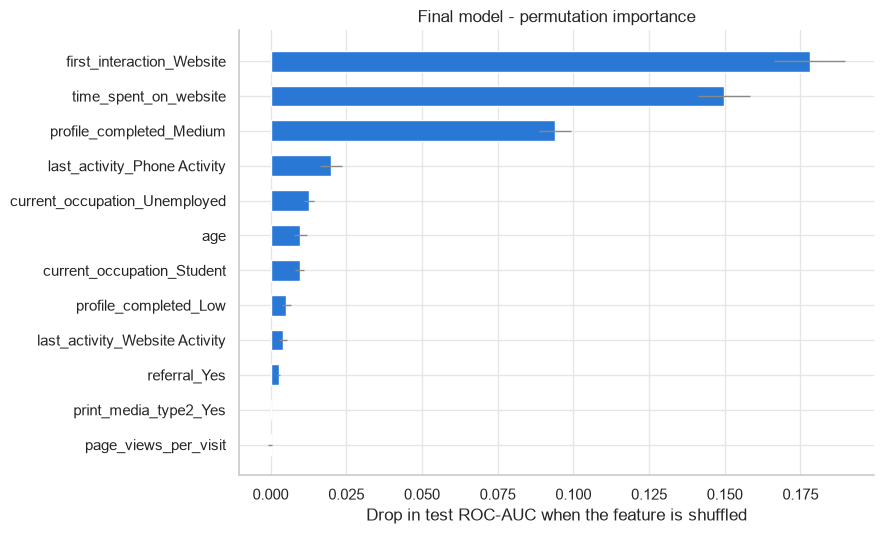

first_interaction_Website         0.1780
time_spent_on_website             0.1497
profile_completed_Medium          0.0940
last_activity_Phone Activity      0.0199
current_occupation_Unemployed     0.0126
age                               0.0099
current_occupation_Student        0.0097
profile_completed_Low             0.0052
last_activity_Website Activity    0.0040
referral_Yes                      0.0027
dtype: float64

In [48]:
from sklearn.inspection import permutation_importance

# Permutation importance on the test set: how much ROC-AUC drops when a feature is shuffled.
# Less biased towards continuous features than the impurity-based importance above.
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=1, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(perm_imp.index[-12:], perm_imp.values[-12:], xerr=pd.Series(perm.importances_std, index=X_test.columns)[perm_imp.index[-12:]],
        color=BLUE, height=0.6, error_kw={"ecolor": GREY, "lw": 1})
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled"); ax.set_title("Final model - permutation importance")
plt.tight_layout(); plt.show()
perm_imp.sort_values(ascending=False).head(10).round(4)

**Observations: final model performance and key drivers**
- The final model catches **84% of the leads who actually convert** on unseen data, and **69% of the leads it flags do convert**, against a 30% base rate. Sales effort aimed at flagged leads is therefore about 2.3 times more productive than contacting leads at random.
- Train and test results are close (recall 0.91 vs 0.84, ROC-AUC 0.96 vs 0.925), so the model generalises well.
- Permutation importance confirms the drivers, in order:
  1. **First interaction via the Website** (vs Mobile App)
  2. **Time spent on the website**
  3. **Profile completion** (`profile_completed_Medium` separates High from Medium completion, since High is the reference level and Low is rare)
  4. Last activity (Phone activity lowers the chance), occupation and age have smaller effects
- The advertising flags (newspaper, magazine, digital, educational channels) add essentially nothing to the model. Referral helps but affects only 2% of leads.

## Profile of leads likely to convert

Every lead is scored with the final model. Leads at or above the threshold are the "likely to convert" group the sales team should prioritise.

In [49]:
scored = df.copy()
scored["p_convert"] = final_model.predict_proba(X)[:, 1]
scored["likely"] = np.where(scored["p_convert"] >= final_thr, "Likely to convert", "Unlikely")
print(scored["likely"].value_counts())
print("Actual conversion rate in each group:")
print(scored.groupby("likely")["status"].mean().round(3))

likely
Unlikely             2902
Likely to convert    1710
Name: count, dtype: int64
Actual conversion rate in each group:
likely
Likely to convert    0.714
Unlikely             0.054
Name: status, dtype: float64


In [50]:
profile_cols = ["first_interaction", "profile_completed", "current_occupation", "last_activity", "referral"]
prof = pd.concat({c: pd.crosstab(scored[c], scored["likely"], normalize="columns") for c in profile_cols})
(prof * 100).round(1)

likely                               Likely to convert  Unlikely
first_interaction  Mobile App                     11.4      64.6
                   Website                        88.6      35.4
profile_completed  High                           71.0      36.2
                   Low                             0.8       3.2
                   Medium                         28.2      60.6
current_occupation Professional                   62.6      53.2
                   Student                         2.9      17.4
                   Unemployed                     34.4      29.4
last_activity      Email Activity                 47.2      50.7
                   Phone Activity                 18.0      31.9
                   Website Activity               34.9      17.4
referral           No                             96.5      98.9
                   Yes                             3.5       1.1

In [51]:
scored.groupby("likely")[num_cols].median().round(1)

,age,website_visits,time_spent_on_website,page_views_per_visit
likely,,,,
Likely to convert,54.0,3.0,653.0,2.8
Unlikely,49.0,3.0,314.0,2.8


In [52]:
# Segment view: conversion rate by the model's top three drivers
seg = scored.assign(time_band=pd.cut(scored.time_spent_on_website, [-1, 415, 3000], labels=["Time <= 415", "Time > 415"]))
seg_tbl = seg.groupby(["first_interaction", "profile_completed", "time_band"], observed=True)["status"].agg(["mean", "count"])
seg_tbl = seg_tbl[seg_tbl["count"] >= 30].sort_values("mean", ascending=False)
seg_tbl.rename(columns={"mean": "conversion_rate", "count": "leads"}).round(3).head(8)

conversion_rate  leads
first_interaction profile_completed time_band                          
Website           High              Time > 415             0.833    587
                  Medium            Time > 415             0.567    545
                  High              Time <= 415            0.516    663
Mobile App        High              Time > 415             0.232    492
                  Medium            Time > 415             0.226    433
Website           Low               Time <= 415            0.160     50
                  Medium            Time <= 415            0.016    684
Mobile App        Medium            Time <= 415            0.009    579

**Profile of a lead likely to convert**

The model flags 1,710 of the 4,612 leads (37%) as likely to convert; 71% of them actually did, against 5% of the rest. (These rates include the training leads and so are slightly optimistic; the test-set precision of 69% is the honest estimate.)

| Characteristic | Likely to convert | Unlikely |
|---|---|---|
| First interaction via **Website** | **89%** | 35% |
| **High** profile completion | **71%** | 36% |
| Median time on website | **653** | 314 |
| Last activity is **Website** | **35%** | 17% |
| Last activity is Phone | 18% | 32% |
| **Professional** | **63%** | 53% |
| Student | 3% | 17% |
| Median age | 54 | 49 |

A typical likely converter is a **working professional (or unemployed career-changer) aged roughly 40–60, who first came to ExtraaLearn through the website, has completed most of their profile, spends a substantial amount of time on the site (above ~415), and engages through website activity such as live chat rather than phone**.

The segment table makes this concrete: **Website-first leads with a High profile who spend more than ~415 on the site convert at 83%** (587 leads), while Mobile App segments convert at 1–23%, and Website leads with a Medium profile and low time on site at 2%.

## Actionable Insights and Recommendations

### Key insights

1. **The website is the conversion engine.** Leads whose first interaction is the website convert at 46% vs 11% for the mobile app, and it is the most important feature in the Decision Tree, Random Forest and XGBoost.
2. **Engagement predicts purchase.** Time on the website is the strongest numeric driver: conversion jumps from under 20% to about 50% above roughly 415–500. Visit count and pages per visit do not matter on their own; *depth* of engagement does.
3. **Profile completion signals intent.** High completion converts at 42% vs 19% (Medium) and 7% (Low).
4. **Professionals are the core market;** students rarely convert (12%).
5. **Self-service beats outbound phone.** Website activity (live chat, profile updates) as the last interaction converts at 38%, phone at 21%.
6. **Referrals convert at 68%** but are only 2% of leads. Paid advertising channels (newspaper, magazine, digital, educational) show no measurable effect on conversion.
7. **The model works.** The tuned Random Forest catches 84% of converters with 69% precision (ROC-AUC 0.925). XGBoost, Gradient Boosting and Random Forest perform almost identically (test ROC-AUC 0.924–0.927), so boosting adds no meaningful gain on this data.

### Recommendations

1. **Score every new lead with the model and prioritise the "likely" group** for representative calls and follow-ups. This concentrates effort on about 37% of leads that contain most of the future customers.
2. **Fix the mobile app experience.** Mobile-first leads convert at only 11%, and even those with a High profile and long website sessions convert at just 23%. Investigate the app journey (course information, pricing, checkout) and consider routing app users to the website or to live chat.
3. **Drive engagement on the website:** richer program pages, demos, webinars and live chat to increase time on site, which is strongly linked to conversion.
4. **Nudge profile completion** with progress bars, reminders and small incentives such as a free lesson for a completed profile.
5. **Invest in a referral programme** (rewards for referrers and referees). It is the highest-converting channel and currently tiny.
6. **Review the advertising budget.** Print and digital ads show no lift in conversion; reallocate spend towards referral and website-engagement initiatives, and run controlled tests before increasing ad spend.
7. **Target marketing at working professionals aged roughly 40–60** looking to upskill. For students, consider lower-priced or financed offerings if they remain a target segment.
8. **Rethink phone outreach:** phone/SMS as the last activity is linked to lower conversion. Use phone for leads the model already rates as likely, and use email or chat for the rest.
9. **Retrain the model regularly** as new lead data arrives, and monitor recall and precision so lead scoring stays accurate.